# Figures and tables for Pedal Poll 2024 paper

## Load and merge data

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
from matplotlib import pyplot as plt
import seaborn as sns
import matplotlib, math
import matplotlib.cm as cm
from matplotlib import rcParams
import contextily as cx
from matplotlib_scalebar.scalebar import ScaleBar

In [2]:
# set options
rcParams['axes.prop_cycle'] = matplotlib.cycler(color=cm.viridis(np.linspace(0.1,1,3))) 
matplotlib.rcParams.update({'font.size': 10})
# load future behaviour to avoid copy warnings
pd.options.mode.copy_on_write = True

In [3]:
agg_counts = pd.read_csv("data/aggregated_data.csv")

In [4]:
canbics = pd.read_csv("data/PP_CounterPoints_Cycle_Facilities_FULL_02JAN2025.csv")
canbics['can_bics_facility'] = canbics['can_bics_facility'].str.strip() # remove leading spaces

In [5]:
# Change North Vancouver to Vancouver
agg_counts.loc[agg_counts['geocoded_city'] == 'North Vancouver', 'geocoded_city'] = 'Vancouver'

In [6]:
# fix mislabeled province for 1 Red Deer count
agg_counts.loc[agg_counts['geocoded_city'] == 'Red Deer', 'geocoded_province'] = 'Alberta'

In [7]:
agg_counts['count_year'] = agg_counts['year']

In [8]:
agg_counts.shape

(1859, 29)

In [9]:
agg_counts = agg_counts.merge(canbics[['grouped_counterpoint_id', 'count_year', 
                                       'can_bics_facility', 'comfort_class', 'other_cycle_facility',
                                       'google_street_month', 'google_street_year']].drop_duplicates(),
                 on = ('grouped_counterpoint_id', 'count_year'), how = 'left')

In [10]:
agg_counts.shape

(1859, 34)

In [11]:
agg_counts['geocoded_province'].unique()

array(['Manitoba', 'Alberta', 'Ontario', 'Saskatchewan', 'Nova Scotia',
       'New Brunswick / Nouveau-Brunswick', 'British Columbia',
       'Newfoundland and Labrador', 'Prince Edward Island', 'Yukon',
       'Quebec', 'BC', 'Northwest Territories', 'New Brunswick'],
      dtype=object)

In [12]:
agg_counts.loc[(agg_counts['geocoded_province'] == 'New Brunswick / Nouveau-Brunswick'), 'geocoded_province'] = "New Brunswick"
agg_counts.loc[(agg_counts['geocoded_province'] == 'BC'), 'geocoded_province'] = "British Columbia"

In [13]:
agg_counts['bikes_per_hour'] = (agg_counts['bike_total'] / agg_counts['total_time_seconds'])*3600

In [14]:
agg_counts[agg_counts['count_session_label'] == 'not_assigned'].groupby('year')['bike_total'].sum()

year
2021    2952
2022     593
2023     250
2024     182
Name: bike_total, dtype: int64

In [15]:
# remove not assigned count sessions
agg_counts = agg_counts[agg_counts['count_session_label'] != 'not_assigned']

In [16]:
agg_counts.shape

(1805, 35)

#### Pivot data

In [17]:
agg_counts['weekday_weekend'] = agg_counts['count_session_label'].str.split('_', expand = True)[0]

In [18]:
# average across all communities, regardless of repeated sites
weekday_weekend_averages = agg_counts.groupby(['weekday_weekend', 'year']).agg(mean = ('bikes_per_hour', 'mean'),
                                                                               std = ('bikes_per_hour', 'std'),
                                                                               count = ('bikes_per_hour', 'nunique')).reset_index()

weekday_weekend_averages = weekday_weekend_averages[weekday_weekend_averages['weekday_weekend'] != 'not'] # remove 'not_assigned' sessions

In [19]:
# pivot to make plotting easier
agg_counts_pivot = pd.pivot_table(agg_counts[['year', 'grouped_counterpoint_id', 'geocoded_city', 'geocoded_province',
       'count_session_label', 'weekday_weekend', 'bike_total', 'bikes_per_hour']],
               values = ['bike_total', 'bikes_per_hour'], index = ['grouped_counterpoint_id', 'geocoded_city', 
                                                                   'geocoded_province', 'count_session_label','weekday_weekend'],
               columns = 'year').reset_index()

## Counterpoint grouping illustration

In [20]:
grouped_counterpoints = pd.read_csv("data/counterpoint_id_groupings.csv")

In [21]:
gdf = gpd.GeoDataFrame(
    grouped_counterpoints, geometry=gpd.points_from_xy(grouped_counterpoints['lng'], grouped_counterpoints['lat']), crs="EPSG:4326")

gdf_grouped = gpd.GeoDataFrame(
    grouped_counterpoints, geometry=gpd.points_from_xy(grouped_counterpoints['grouped_counterpoint_lng'], 
                                                       grouped_counterpoints['grouped_counterpoint_lat']), crs="EPSG:4326")

In [22]:
london = gdf[gdf['geocoded_city'] == 'London']

In [23]:
sample_ids = london.cx[-81.26:-81.22, 42.96:43]['counterpoint_id'].unique()

In [24]:
sample = london[london['counterpoint_id'].isin(sample_ids)]
sample2 = gdf[gdf['geocoded_city'] == 'Toronto'].cx[-79.39:-79.37,43.64:43.66]

In [25]:
# use local crs to preserve orientation as best as possible
sample = sample.to_crs(sample.estimate_utm_crs())
sample2 = sample2.to_crs(sample2.estimate_utm_crs())

In [26]:
sample_grouped = gdf_grouped[gdf_grouped['counterpoint_id'].isin(sample_ids)]
sample_grouped = sample_grouped.to_crs(sample.crs)

sample2_grouped = gdf_grouped[gdf_grouped['counterpoint_id'].isin(sample2['counterpoint_id'])]
sample2_grouped = sample2_grouped.to_crs(sample2.crs)

In [27]:
# restrict to grouped counterpoint id
sample_grouped = sample_grouped[sample_grouped['counterpoint_id'] == sample_grouped['grouped_counterpoint_id']]
sample2_grouped = sample2_grouped[sample2_grouped['counterpoint_id'] == sample2_grouped['grouped_counterpoint_id']]

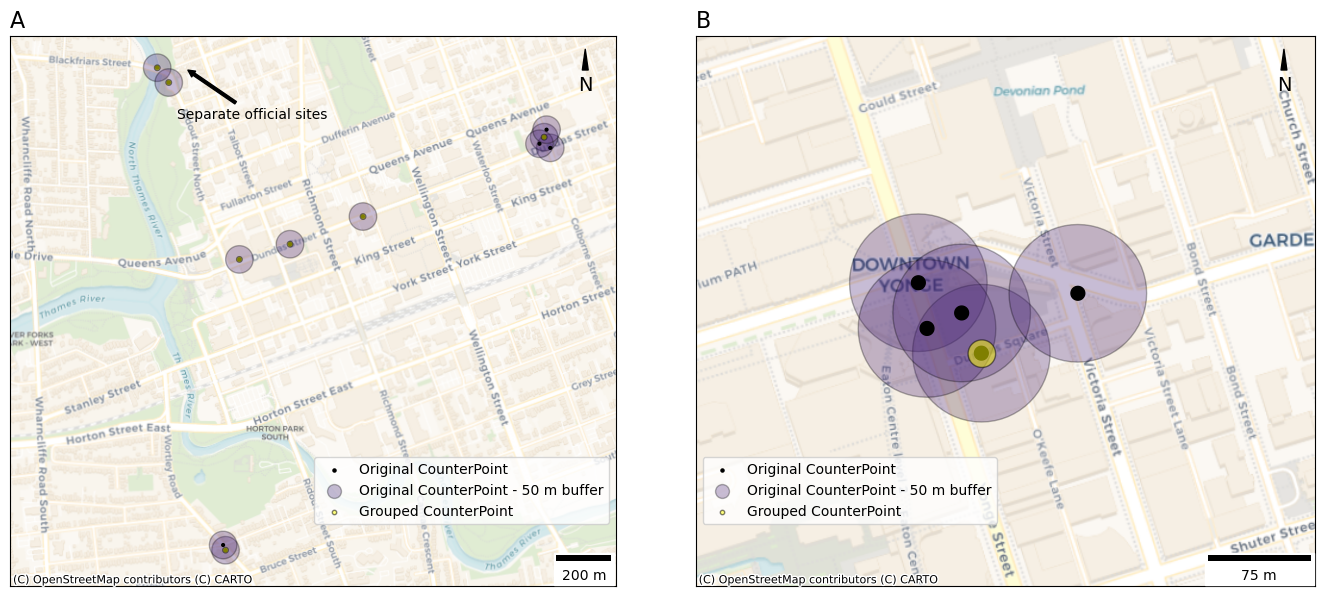

In [28]:
# example: London, ON
fig, axs = plt.subplots(1,2, figsize = (14,6))

ax = axs[0]
sample.drop_duplicates(subset = 'counterpoint_id').buffer(50).plot(ax = ax, alpha = 0.3, edgecolor = 'k')
sample.drop_duplicates(subset = 'counterpoint_id').buffer(5).plot(ax = ax, edgecolor = 'k', color = 'k')
sample_grouped.drop_duplicates(subset = 'grouped_counterpoint_id').buffer(10).plot(ax = ax, alpha = 0.5, edgecolor = 'k', color = 'yellow')
cx.add_basemap(ax, crs = sample.crs, source=cx.providers.CartoDB.Voyager, zoom = 15)

ax.add_artist(ScaleBar(1, location = 'lower right'))
ax.annotate("N", fontsize = 14, xy=(0.95,0.98), xytext=(0.95, 0.9), xycoords = 'axes fraction', horizontalalignment='center', arrowprops=dict(facecolor='black', 
                                                                                                                           arrowstyle='wedge'))

ax.annotate("Separate official sites", 
            xy=(0.29,0.94), xytext=(0.4, 0.85), xycoords = 'axes fraction', horizontalalignment='center', arrowprops=dict(facecolor='black', 
                                                                                                                           arrowstyle='simple'))
# dummy data for legend
ax.scatter([0],[0], edgecolor = 'k', s = 5, color = 'k', label = 'Original CounterPoint')
ax.scatter([0],[0], alpha = 0.3, edgecolor = 'k', s = 100, label = 'Original CounterPoint - 50 m buffer')
ax.scatter([0],[0], alpha = 0.5, edgecolor = 'k', color = 'yellow', s = 10, label = 'Grouped CounterPoint')

ax.set_xlim(4.785e5, 4.807e5)
ax.set_ylim(4.75775e6, 4.75975e6)

ax.legend(loc = 'lower right', bbox_to_anchor=(1,0.1))

ax.set_title("A", fontsize = 16, loc = 'left')

ax.set_yticks([])
ax.set_xticks([])


ax1 =axs[1]
sample2.drop_duplicates(subset = 'counterpoint_id').buffer(50).plot(ax = ax1, alpha = 0.3, edgecolor = 'k')
sample2.drop_duplicates(subset = 'counterpoint_id').buffer(5).plot(ax = ax1, edgecolor = 'k', color = 'k')
sample2_grouped.drop_duplicates(subset = 'grouped_counterpoint_id').buffer(10).plot(ax = ax1, alpha = 0.5, edgecolor = 'k', color = 'yellow')

ax1.set_xlim(6.304e5, 6.3085e5)
ax1.set_ylim(4.83475e6, 4.83515e6)

cx.add_basemap(ax1, crs = sample2.crs, source=cx.providers.CartoDB.Voyager, zoom = 17)

# dummy data for legend
ax1.scatter([0],[0], edgecolor = 'k', s = 5, color = 'k', label = 'Original CounterPoint')
ax1.scatter([0],[0], alpha = 0.3, edgecolor = 'k', s = 100, label = 'Original CounterPoint - 50 m buffer')
ax1.scatter([0],[0], alpha = 0.5, edgecolor = 'k', color = 'yellow', s = 10, label = 'Grouped CounterPoint')

ax1.add_artist(ScaleBar(1, location = 'lower right'))
ax1.annotate("N", fontsize = 14, xy=(0.95,0.98), xytext=(0.95, 0.9), xycoords = 'axes fraction', 
             horizontalalignment='center', arrowprops=dict(facecolor='black', arrowstyle='wedge'))

ax1.set_title("B", fontsize = 16, loc = 'left')

ax1.legend(loc = 'lower left', bbox_to_anchor=(0,0.1))

ax1.set_xticks([])
ax1.set_yticks([])

plt.tight_layout()

plt.savefig("counterpoint_grouping_example.pdf")

## Summary table

- as in first paper: totals by province, total communities, total count time

In [29]:
agg_counts['other_cycle_facility'] = agg_counts['other_cycle_facility'].str.strip()

In [30]:
# use the explicity type in "other infrastructre" for clarity
agg_counts['combined_facility'] = agg_counts['other_cycle_facility'].fillna(agg_counts['can_bics_facility'])

In [31]:
agg_counts['combined_facility'].unique()

array([nan, 'Cycle track', 'Local street shared roadway',
       'Not classified', 'Multi-use path', 'Major street shared lane',
       'Painted bike lane', 'Multi-use trail', 'Local street bikeway',
       'Bike path'], dtype=object)

In [32]:
num_sessions = agg_counts[agg_counts['count_session_label'] != 'not_assigned'].groupby(['year', 'grouped_counterpoint_id', 'count_session_label', 'start_datetime_dayofmonth'])['bike_total'].count().reset_index()

In [33]:
num_sessions.shape

(1805, 5)

In [34]:
agg_counts['grouped_counterpoint_id'].unique().shape

(413,)

In [35]:
agg_counts['bike_total'].sum()

np.int64(200607)

In [36]:
agg_counts['geocoded_city'].unique().shape

(60,)

In [37]:
for year in [2021, 2022, 2023, 2024]:
    tot_bikes = agg_counts[agg_counts['year'] == year]['bike_total'].sum()
    tot_locations = agg_counts[agg_counts['year'] == year]['grouped_counterpoint_id'].unique().shape[0]
    tot_communities = agg_counts[agg_counts['year'] == year]['geocoded_city'].unique().shape[0]
    tot_hours = round(agg_counts[agg_counts['year'] == year]['total_time_seconds'].sum() / 3600, 1)
    print(year, tot_bikes, " bikes counted in ", tot_locations, " locations in ", tot_communities, " communities, ", tot_hours, " hours, and ",
         num_sessions[num_sessions['year'] == year].shape[0], " sessions.")

2021 76783  bikes counted in  253  locations in  50  communities,  1136.6  hours, and  654  sessions.
2022 48538  bikes counted in  218  locations in  38  communities,  855.9  hours, and  485  sessions.
2023 28253  bikes counted in  159  locations in  32  communities,  502.2  hours, and  299  sessions.
2024 47033  bikes counted in  167  locations in  31  communities,  681.5  hours, and  367  sessions.


In [38]:
summary_table = agg_counts.groupby(["geocoded_province", "year"])[["bike_total", "total_time_seconds",
                                                                   "grouped_counterpoint_id"]].agg({'bike_total':'sum', 
                                                                                                    'total_time_seconds':'sum', 
                                                                                                    'grouped_counterpoint_id':'nunique'}).reset_index()

In [39]:
summary_table['total_time_hours'] = round(summary_table['total_time_seconds'] / 3600,0)

In [40]:
summary_table_pivot = pd.pivot_table(summary_table[['geocoded_province',
       'bike_total', 'total_time_hours', 'grouped_counterpoint_id', 'year']],
               values = ['bike_total', 'total_time_hours', 'grouped_counterpoint_id'], index = ['geocoded_province'],
               columns = 'year').reset_index()

In [41]:
summary_table_pivot = summary_table_pivot.fillna(0)

In [42]:
summary_table_pivot['bike_total'] = summary_table_pivot['bike_total'].astype('int')
summary_table_pivot['total_time_hours'] = summary_table_pivot['total_time_hours'].astype('int')
summary_table_pivot['grouped_counterpoint_id'] = summary_table_pivot['grouped_counterpoint_id'].astype('int')

In [43]:
summary_table_pivot['total_hours'] = summary_table_pivot['total_time_hours'].sum(axis = 1)

In [44]:
# total unique sites
summary_table_pivot['unique_sites'] = agg_counts.groupby('geocoded_province')['grouped_counterpoint_id'].nunique().values

In [45]:
province_abbr = {'Alberta':'AB', 'British Columbia':'BC', 'Manitoba':'MB', 'New Brunswick':'NB',
       'Newfoundland and Labrador':'NL', 'Northwest Territories':'NT',
       'Nova Scotia':'NS', 'Ontario':'ON', 'Prince Edward Island':'PE', 'Quebec':'QC',
       'Saskatchewan':'SK', 'Yukon':'YT'}

In [46]:
summary_table_pivot['province_abbr'] = summary_table_pivot['geocoded_province'].map(province_abbr)

In [47]:
summary_table_pivot['province'] = summary_table_pivot['geocoded_province'] + ' (' + summary_table_pivot['province_abbr'] + ')'

In [48]:
summary_table = summary_table_pivot.sort_values(by = 'total_hours', ascending = False)

summary_table = summary_table[['province', 'province_abbr', 'bike_total', 'total_time_hours', 'grouped_counterpoint_id', 'unique_sites']]

In [49]:
summary_table

province province_abbr bike_total                \
year                                                     2021   2022   2023   
7                       Ontario (ON)            ON      28595  18063  13685   
0                       Alberta (AB)            AB       3253   4609   3115   
1              British Columbia (BC)            BC      30731  17815   5789   
6                   Nova Scotia (NS)            NS       2325   1706    867   
2                      Manitoba (MB)            MB       4411   2298   1308   
10                 Saskatchewan (SK)            SK       1642   1595   1016   
11                        Yukon (YT)            YT        714    352    675   
4     Newfoundland and Labrador (NL)            NL        338    103     20   
8          Prince Edward Island (PE)            PE        296    185    112   
3                 New Brunswick (NB)            NB        571    493      2   
9                        Quebec (QC)            QC       3907   1266   1664   
5         Northwest Territories (NT)            NT          0     53      0   

            total_time_hours                grouped_counterpoint_id            \
year   2024             2021 2022 2023 2024                    2021 2022 2023   
7     19015              481  375  275  329                     102   89   76   
0      3247               99  166   53   82                      29   41   18   
1     10042              172  111   50   56                      42   30   24   
6      1672              116   64   41   58                      22   16   12   
2      1341              102   34   17   26                      16   10    6   
10      644               40   35   17   31                       8   11    5   
11     1097               30   19   26   31                       5    4    7   
4         1               38   20    6    1                      10    5    4   
8       229               22   10   11   15                       5    3    4   
3       442               18   12    2   11                       7    5    1   
9      8333               18    8    4   12                       7    3    2   
5       970                0    2    0   31                       0    1    0   

          unique_sites  
year 2024               
7      74          169  
0      23           63  
1      14           60  
6      15           32  
2       6           18  
10     11           17  
11      6           11  
4       1           12  
8       3            5  
3       4           10  
9       4           10  
5       6            6

Summary table 2: count session totals

In [50]:
# make a column for the combination of location and session
agg_counts['location_session'] = agg_counts['grouped_counterpoint_id'].astype('int').astype('str') + "_" + agg_counts['count_session_label']

In [51]:
count_sessions = agg_counts[['location_session', 'combined_facility', 'year']].dropna()

In [52]:
year_sessions_list = agg_counts[['location_session', 'combined_facility', 'year']].dropna().drop_duplicates()

In [53]:
year_sessions_list = year_sessions_list.groupby('location_session')['year'].count().reset_index().sort_values(by = 'year')

In [54]:
multi_year_sessions = year_sessions_list[year_sessions_list['year'] > 1]['location_session']
all_year_sessions = year_sessions_list[year_sessions_list['year'] == 4]['location_session']

In [55]:
count_sessions['count'] = 1

In [56]:
count_sessions_grouped = count_sessions.groupby(['year', 'combined_facility'])['location_session'].count().reset_index()

In [57]:
count_sessions_pivot = pd.pivot_table(count_sessions_grouped, columns = 'combined_facility', index = ['year'], values = 'location_session').reset_index()

In [58]:
count_sessions_pivot

combined_facility,year,Bike path,Cycle track,Local street bikeway,Local street shared roadway,Major street shared lane,Multi-use path,Multi-use trail,Not classified,Painted bike lane
0,2021,25.0,63.0,27.0,18.0,15.0,189.0,34.0,113.0,30.0
1,2022,14.0,77.0,40.0,2.0,7.0,200.0,17.0,89.0,39.0
2,2023,8.0,58.0,15.0,9.0,4.0,128.0,10.0,48.0,19.0
3,2024,12.0,82.0,27.0,7.0,6.0,140.0,12.0,57.0,24.0


In [59]:
count_sessions_pivot['High comfort'] = count_sessions_pivot['Bike path'] + count_sessions_pivot['Cycle track'] + count_sessions_pivot['Local street bikeway']
count_sessions_pivot['Shared or signed roadway'] = count_sessions_pivot['Local street shared roadway'] + count_sessions_pivot['Major street shared lane']

In [60]:
count_sessions_pivot.columns

Index(['year', 'Bike path', 'Cycle track', 'Local street bikeway',
       'Local street shared roadway', 'Major street shared lane',
       'Multi-use path', 'Multi-use trail', 'Not classified',
       'Painted bike lane', 'High comfort', 'Shared or signed roadway'],
      dtype='object', name='combined_facility')

In [61]:
# reorder columns
count_sessions_pivot = count_sessions_pivot[['year', 'High comfort', 'Multi-use path', 'Painted bike lane', 'Multi-use trail', 
                                             'Shared or signed roadway', 'Not classified']]

In [62]:
assert agg_counts['combined_facility'].dropna().shape[0] == count_sessions_pivot[['High comfort', 'Multi-use path', 'Painted bike lane', 'Multi-use trail', 
                                             'Shared or signed roadway', 'Not classified']].sum().sum()

In [63]:
# add multi-year site columns

In [64]:
list(count_sessions[count_sessions['location_session'].isin(multi_year_sessions)].groupby('year')['combined_facility'].count())

[324, 321, 233, 254]

In [65]:
count_sessions_pivot['single_year_counts'] = list(count_sessions[~(count_sessions['location_session'].isin(multi_year_sessions))].groupby('year')['combined_facility'].count())

In [66]:
count_sessions_pivot['multi_year_counts'] = list(count_sessions[count_sessions['location_session'].isin(multi_year_sessions)].groupby('year')['combined_facility'].count())

In [67]:
count_sessions_pivot['all_year_counts'] = list(count_sessions[count_sessions['location_session'].isin(all_year_sessions)].groupby('year')['combined_facility'].count())

In [68]:
count_sessions_pivot

combined_facility,year,High comfort,Multi-use path,Painted bike lane,Multi-use trail,Shared or signed roadway,Not classified,single_year_counts,multi_year_counts,all_year_counts
0,2021,115.0,189.0,30.0,34.0,33.0,113.0,190,324,42
1,2022,131.0,200.0,39.0,17.0,9.0,89.0,164,321,39
2,2023,81.0,128.0,19.0,10.0,13.0,48.0,66,233,40
3,2024,121.0,140.0,24.0,12.0,13.0,57.0,113,254,38


It can happen that multiple sessions are counted at the same slot in the same year. For example, at CounterPoint 343 in Winnipeg, Manitoba, the weekday afternoon count session was counted four times in 2021 on each day from Tuesday through Friday. 

In [69]:
agg_counts[(agg_counts['grouped_counterpoint_id'] == 343) 
    & (agg_counts['count_session_label'] == 'weekday_afternoon')]

,year,grouped_counterpoint_id,geocoded_city,geocoded_province,start_datetime_dayofmonth,count_session_label,bike_total,pedestrian_total,personal_vehicle_total,oversized_vehicle_total,...,count_year,can_bics_facility,comfort_class,other_cycle_facility,google_street_month,google_street_year,bikes_per_hour,weekday_weekend,combined_facility,location_session
8,2021,343.0,Winnipeg,Manitoba,1,weekday_afternoon,172,NaN,NaN,NaN,...,2021,Non-conforming,NaN,Local street shared roadway,MAY,2019.0,86.722689,weekday,Local street shared roadway,343_weekday_afternoon
11,2021,343.0,Winnipeg,Manitoba,2,weekday_afternoon,220,NaN,NaN,NaN,...,2021,Non-conforming,NaN,Local street shared roadway,MAY,2019.0,110.000000,weekday,Local street shared roadway,343_weekday_afternoon
12,2021,343.0,Winnipeg,Manitoba,3,weekday_afternoon,202,NaN,NaN,NaN,...,2021,Non-conforming,NaN,Local street shared roadway,MAY,2019.0,101.000000,weekday,Local street shared roadway,343_weekday_afternoon
13,2021,343.0,Winnipeg,Manitoba,4,weekday_afternoon,145,NaN,NaN,NaN,...,2021,Non-conforming,NaN,Local street shared roadway,MAY,2019.0,72.500000,weekday,Local street shared roadway,343_weekday_afternoon
688,2022,343.0,Winnipeg,Manitoba,7,weekday_afternoon,231,NaN,NaN,NaN,...,2022,Cycle track,High,NaN,JUN,2022.0,115.500000,weekday,Cycle track,343_weekday_afternoon
1183,2023,343.0,Winnipeg,Manitoba,6,weekday_afternoon,88,56.0,205.0,6.0,...,2023,Cycle track,High,NaN,JUN,2022.0,160.000000,weekday,Cycle track,343_weekday_afternoon
1491,2024,343.0,Winnipeg,Manitoba,4,weekday_afternoon,107,232.0,584.0,19.0,...,2024,Cycle track,High,NaN,JUN,2022.0,43.461582,weekday,Cycle track,343_weekday_afternoon


In [70]:
for col in count_sessions_pivot.columns:
    count_sessions_pivot[col] = count_sessions_pivot[col].astype('int')

In [71]:
count_sessions_pivot.loc[4] = [r'\textbf{Total}'] + list(count_sessions_pivot.sum(axis = 0))[1:]

In [72]:
assert np.all(count_sessions_pivot[['High comfort', 'Multi-use path', 'Painted bike lane', 'Multi-use trail', 
                                             'Shared or signed roadway', 'Not classified']].sum(axis = 1) 
              == count_sessions_pivot[['multi_year_counts', 'single_year_counts']].sum(axis = 1))

In [73]:
count_sessions_pivot['total sessions'] = count_sessions_pivot[['multi_year_counts', 'single_year_counts']].sum(axis = 1)

In [74]:
count_sessions_pivot.to_csv("count_sessions_stats.csv", index = None)

### Figure 1: total bikes counted and hours counted

In [75]:
summary_table.columns = summary_table.columns.get_level_values(0)

In [76]:
summary_table.columns = ['province',  'province_abbr',      'bike_total_2021',        'bike_total_2022',
              'bike_total_2023',        'bike_total_2024',  'total_time_hours_2021',
        'total_time_hours_2022',  'total_time_hours_2023',  'total_time_hours_2024',
                        'unique_sites_2021', 'unique_sites_2022', 'unique_sites_2023', 'unique_sites_2024', 'total_unique_sites']

In [77]:
markers = ['o','x','s','^']

In [78]:
colors = sns.color_palette('husl', 12)
colors = np.concatenate([colors[::2], colors[1::2]]) # alternate

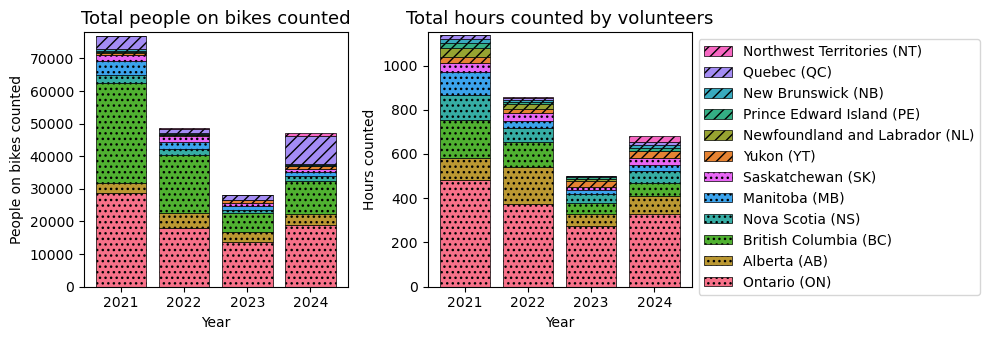

In [79]:
fig, axs = plt.subplots(1,2, figsize = (10,3.5))

#df_plot = on_street_grouped[on_street_grouped['weekday_weekend'] == week].sort_values(by = 'comfort_class')
years = [2021,2022,2023,2024]
bottom = np.zeros(len(years))

#mode_colours = ['green', 'blue', 'gold', 'red']
#mode_labels = ['Bikes', 'Pedestrians', 'Personal vehicles', 'Oversized vehicles']
count = 0
for i, row in summary_table.iterrows():
    vals = row[[ 'bike_total_2021', 'bike_total_2022', 'bike_total_2023', 'bike_total_2024']].values.astype('int')
    bars = axs[0].bar(years, list(vals), bottom = bottom, label = row['province'], color = colors[count], edgecolor = 'k', linewidth = 0.5)
    if count > 5:
        for b in bars:
            b.set_hatch('///')
            
    else:
        for b in bars:
            b.set_hatch('...')
    bottom += vals
    count += 1



axs[0].set_xticks(years);


axs[0].set_xlabel("Year")

bottom = np.zeros(len(years))

#mode_colours = ['green', 'blue', 'gold', 'red']
#mode_labels = ['Bikes', 'Pedestrians', 'Personal vehicles', 'Oversized vehicles']
count = 0
for i, row in summary_table.iterrows():
    vals = row[['total_time_hours_2021',
        'total_time_hours_2022',  'total_time_hours_2023',  'total_time_hours_2024']].values.astype('int')
    bars = axs[1].bar(years, list(vals), bottom = bottom, label = row['province'], color = colors[count], edgecolor = 'k', linewidth = 0.5)
    if count > 5:
        for b in bars:
            b.set_hatch('///')
            
    else:
        for b in bars:
            b.set_hatch('...')
    bottom += vals
    count += 1

    
handles, labels = axs[1].get_legend_handles_labels()
axs[1].legend(list(reversed(handles)), list(reversed(labels)), loc='upper left', bbox_to_anchor = (1,1), fontsize = 10)
axs[1].set_xticks(years);

axs[1].set_xlabel("Year")

axs[1].set_ylabel("Hours counted")
axs[0].set_ylabel("People on bikes counted")
axs[0].set_title("Total people on bikes counted", fontsize = 13)
axs[1].set_title("Total hours counted by volunteers", fontsize = 13)

axs[0].set_ylim(0,78000)
axs[1].set_ylim(0,1150)

plt.tight_layout()
plt.savefig("total_bikes_and_hours.pdf")
plt.savefig("total_bikes_and_hours.png", dpi = 300)

### Format Table 1

In [80]:
summary_table_save = summary_table.drop(columns = 'province')

In [81]:
totals = list(summary_table_save.sum(axis = 0).values)

In [82]:
totals[0] = r'\textbf{Total}'

In [83]:
summary_table_save.loc[100] = totals

In [84]:
import re
def thous(x, sep=',', dot='.'):
    num, _, frac = str(x).partition(dot)
    num = re.sub(r'(\d{3})(?=\d)', r'\1'+sep, num[::-1])[::-1]
    if frac:
        num += dot + frac
    return num

In [85]:
for col in ['bike_total_2021',        'bike_total_2022',
              'bike_total_2023',        'bike_total_2024']:
    summary_table_save[col] = summary_table_save[col].astype('object')
    summary_table_save.loc[:, col] = summary_table_save[col].apply(lambda x: thous(x, sep = ','))

In [86]:
summary_table_save.columns

Index(['province_abbr', 'bike_total_2021', 'bike_total_2022',
       'bike_total_2023', 'bike_total_2024', 'total_time_hours_2021',
       'total_time_hours_2022', 'total_time_hours_2023',
       'total_time_hours_2024', 'unique_sites_2021', 'unique_sites_2022',
       'unique_sites_2023', 'unique_sites_2024', 'total_unique_sites'],
      dtype='object')

In [87]:
summary_table_save.to_csv("summary_table.csv", index = None, sep = ';')

### Summary stats

In [88]:
# total bikes across all four years
agg_counts['bike_total'].sum()

np.int64(200607)

In [89]:
# Unique communities
len(agg_counts['geocoded_city'].unique())

60

In [90]:
# unique sessions
len(agg_counts)

1805

In [91]:
agg_counts['grouped_counterpoint_id'].drop_duplicates().shape[0]

413

In [92]:
agg_counts.dropna(subset = 'combined_facility')['grouped_counterpoint_id'].drop_duplicates().shape[0]

306

In [93]:
for year in [2021, 2022, 2023, 2024]:
    print(agg_counts[(agg_counts['count_session_label'] != 'not_assigned')
                    & (agg_counts['year'] == year)].shape[0])

654
485
299
367


In [94]:
agg_counts.groupby('comfort_class')['bikes_per_hour'].median()

comfort_class
High      74.601770
Low       19.202426
Medium    28.108108
Name: bikes_per_hour, dtype: float64

In [95]:
np.median(agg_counts[agg_counts['comfort_class'] == 'High']['bikes_per_hour'])

np.float64(74.60176991150442)

In [96]:
np.median(agg_counts['bikes_per_hour'])

np.float64(27.98993825748914)

In [97]:
np.quantile(agg_counts['bikes_per_hour'], 0.99)

np.float64(548.3541190382344)

In [98]:
len(agg_counts[agg_counts['grouped_counterpoint_id'] == 5542])

11

In [99]:
agg_counts[agg_counts['grouped_counterpoint_id'] == 5542]['bikes_per_hour'].median()

np.float64(429.0)

In [100]:
len(agg_counts[agg_counts['grouped_counterpoint_id'] == 5608])

8

In [101]:
agg_counts[agg_counts['grouped_counterpoint_id'] == 5608]['bikes_per_hour'].median()

np.float64(380.38768718802)

In [102]:
agg_counts[agg_counts['bikes_per_hour'] > np.quantile(agg_counts['bikes_per_hour'], 
                                                      0.99)].sort_values('bikes_per_hour')[['geocoded_city', 'grouped_counterpoint_id', 'bike_total', 'bikes_per_hour', 'comfort_class']]

,geocoded_city,grouped_counterpoint_id,bike_total,bikes_per_hour,comfort_class
805,Vancouver,5312.0,1079,548.644068,High
228,Vancouver,5312.0,1190,557.812500,High
1687,Toronto,5542.0,1156,562.378378,High
555,Montreal,5585.0,1081,564.000000,High
517,Toronto,5542.0,1280,568.888889,High
187,Vancouver,5302.0,1187,598.487395,High
811,Vancouver,5313.0,1197,603.529412,High
788,Vancouver,5302.0,1198,609.152542,High
570,Montreal,5608.0,1235,633.333333,High
932,Toronto,5542.0,1336,722.162162,High


## Can-BICS

In [103]:
rcParams['axes.prop_cycle'] = matplotlib.cycler(color=cm.viridis(np.linspace(0,1,4))) 

In [104]:
comfort_mapping = {'Low':0,  'High':2, 'Medium':1}

In [105]:
#using https://chatrlab.ca/wp-content/uploads/2022/09/canbics-graphic-no-title.png?w=1024
# and https://imagecolorpicker.com/
highcolour = '#37a76f'
mediumcolour = '#92d14f'
lowcolour = '#a5a5a5'
nonconformcolour = '#cfae3c'
nocolour = '#73accb'

In [106]:
agg_counts['comfort_class_int'] = agg_counts['comfort_class'].map(comfort_mapping)

In [107]:
agg_counts[agg_counts['can_bics_facility'] == 'Non-conforming']['other_cycle_facility'].unique()

array(['Local street shared roadway', 'Major street shared lane',
       'Multi-use trail'], dtype=object)

In [108]:
facility_dict_full = {'Painted bike lane':'Painted bike lane', 'Cycle track':'Cycle track',
       'Not classified':'No infrastructure', 'Multi-use path':'Multi-use path', 'Local street bikeway':'Local street bikeway',
       'Bike path': 'Bike path',
        'Local street shared roadway':'Signed or marked\nshared roadway', 
        'Major street shared lane':'Signed or marked\nshared roadway',
       'Multi-use trail':'Unpaved multi-use trail'}

facility_dict = {'Painted bike lane':'Painted bike lane', 'Cycle track':'Cycle track',
       'Not classified':'No infrastructure', 'Multi-use path':'Multi-use path', 'Local street bikeway':'Local street bikeway',
       'Bike path': 'Bike path',
        'Local street shared roadway':'Other infrastructure', 
        'Major street shared lane':'Other infrastructure',
       'Multi-use trail':'Other infrastructure'}

In [109]:
agg_counts['facility_label_full'] = agg_counts['combined_facility'].map(facility_dict_full)
agg_counts['facility_label'] = agg_counts['combined_facility'].map(facility_dict)

In [110]:
# put no infrastructure last
agg_counts.loc[(agg_counts['other_cycle_facility'].isna())
               & (agg_counts['comfort_class'].isna()), 'comfort_class_int'] = -2

agg_counts.loc[~(agg_counts['other_cycle_facility'].isna())
               & (agg_counts['comfort_class'].isna()), 'comfort_class_int'] = -1

In [111]:
agg_counts_canbics = agg_counts[~agg_counts['can_bics_facility'].isna()] # remove na
#agg_counts_canbics = agg_counts_canbics[agg_counts_canbics['can_bics_facility'] != 'Not classified']

In [112]:
agg_counts_canbics['facility_label_full'].value_counts()

facility_label_full
Multi-use path                      657
No infrastructure                   307
Cycle track                         280
Painted bike lane                   112
Local street bikeway                109
Unpaved multi-use trail              73
Signed or marked\nshared roadway     68
Bike path                            59
Name: count, dtype: int64

In [113]:
agg_counts_canbics.shape

(1665, 41)

/tmp/ipykernel_41753/154649673.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right')


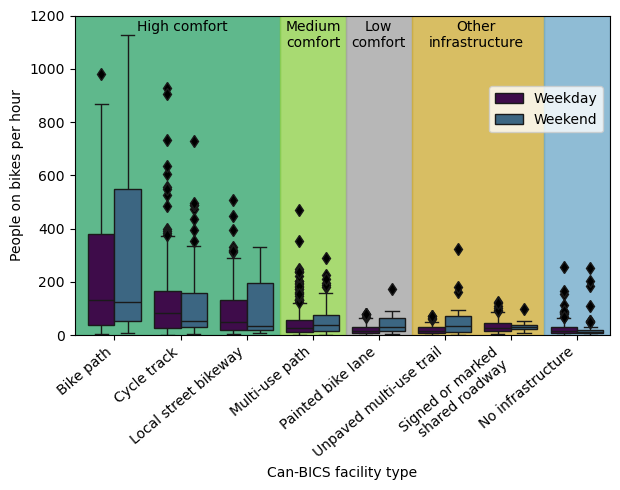

In [114]:
fig, ax = plt.subplots(figsize = (6.3,5))

sns.boxplot(data=agg_counts_canbics[
    (agg_counts_canbics['weekday_weekend'] != 'not')].sort_values(by = 'comfort_class_int', 
                                                                                      ascending = False),
            x = 'facility_label_full', y = 'bikes_per_hour', hue = 'weekday_weekend',
           ax = ax, flierprops={"marker": "d", "mfc": "k"});

ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right')
ax.fill_between([-1,2.5], y1=0,y2=1750, color=highcolour, alpha = 0.8, zorder = 0)
ax.fill_between([2.5,3.5], y1=0,y2=1750, color=mediumcolour, alpha = 0.8, zorder = 0)
ax.fill_between([3.5,4.5], y1=0,y2=1750, color=lowcolour, alpha = 0.8, zorder = 0)
ax.fill_between([4.5,6.5], y1=0,y2=1750, color=nonconformcolour, alpha = 0.8, zorder = 0)
ax.fill_between([6.5,7.5], y1=0,y2=1750, color=nocolour, alpha = 0.8, zorder = 0)
ax.set_xlabel("Can-BICS facility type")
ax.set_xlim(-0.6, 7.5)
ax.set_ylim(0,1200)
ax.set_ylabel("People on bikes per hour")

h, l = ax.get_legend_handles_labels()
legend_labels = []
for lab in l:
    legend_labels.append(lab.capitalize())

loc = 'upper right'
pos = (1,0.8)
ax.legend(h, legend_labels, title = "", loc = 'upper right', bbox_to_anchor = pos)

ax.annotate("High comfort", xy=(0.20, 0.95), xycoords = 'axes fraction', ha = 'center')
ax.annotate("Medium\ncomfort", xy=(0.445, 0.9), xycoords = 'axes fraction', ha = 'center')
ax.annotate("Low\ncomfort", xy=(0.567, 0.9), xycoords = 'axes fraction', ha = 'center')
ax.annotate("Other\ninfrastructure", xy=(0.750, 0.9), xycoords = 'axes fraction', ha = 'center')

plt.tight_layout()
plt.savefig("canbics_all.pdf")
plt.savefig("canbics_all.png", dpi = 300)

### Can-BICS Summary table

In [115]:
agg_counts_canbics['combined_comfort_class'] = agg_counts_canbics['comfort_class'].fillna(agg_counts_canbics['can_bics_facility'])

In [116]:
agg_counts_canbics['combined_comfort_class'].unique()

array(['High', 'Non-conforming', 'Not classified', 'Medium', 'Low'],
      dtype=object)

In [117]:
canbics_provinces = agg_counts_canbics.groupby(["geocoded_province", "year", "combined_comfort_class"])["bike_total"].count().reset_index()

In [118]:
# total counts by province and year
counts_by_province = pd.pivot_table(agg_counts_canbics.groupby(["geocoded_province", "year"])['bike_total'].count().reset_index()[['geocoded_province',
        'year', 'bike_total']],
               values = ['bike_total'], index = ['geocoded_province'],
               columns = ['year']).reset_index()

In [119]:
counts_by_province.columns = ['geocoded_province', 2021, 2022, 2023, 2024]

In [120]:
canbics_provinces['province_abbr'] = canbics_provinces['geocoded_province'].map(province_abbr)

Show Can-BICS as bar chart instead of tables

In [121]:
provinces = list(summary_table['province'].str.split('(', expand = True)[1].str.split(')', expand = True)[0])

Use a perceptually uniform colormap for categories, then adjust lightness for years

In [122]:
#from https://stackoverflow.com/questions/37765197/darken-or-lighten-a-color-in-matplotlib
def adjust_lightness(color, amount=0.5):
    """
    Amount < 1 darkens colour, amount > 1 lightens colour.
    """
    import matplotlib.colors as mc
    import colorsys
    try:
        c = mc.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mc.to_rgb(c))
    return colorsys.hls_to_rgb(c[0], max(0, min(1, amount * c[1])), c[2])

In [123]:
sorterIndex = dict(zip(provinces, range(len(provinces))))

In [124]:
for label, group in canbics_provinces.groupby(['year', 'combined_comfort_class']):
    # sort by desired province order

    missing_provinces = set(provinces) - set(group['province_abbr'])
    df = pd.DataFrame()
    df['province_abbr'] = list(group['province_abbr']) + list(missing_provinces)
    df['count_sites'] = list(group['bike_total']) + [0]*len(missing_provinces)
    df = df.sort_values(by = 'province_abbr', key=lambda x: x.map(sorterIndex))

    # fill in any missing data

In [125]:
colors = cm.viridis(np.linspace(0,0.95,5))

In [126]:
# sort by comfort class order
comfort_classes = ['High',  'Medium', 'Low', 'Non-conforming', 'Not classified']
sorterIndex2 = dict(zip(comfort_classes, range(len(comfort_classes))))
canbics_provinces['comfort_class_sort'] = canbics_provinces['combined_comfort_class'].map(sorterIndex2)
canbics_provinces = canbics_provinces.sort_values(by = ['year', 'combined_comfort_class'])

In [127]:
colors = np.array([matplotlib.colors.to_rgba(highcolour), 
                   matplotlib.colors.to_rgba(mediumcolour), 
                   matplotlib.colors.to_rgba(lowcolour), 
                   matplotlib.colors.to_rgba(nonconformcolour), 
                   matplotlib.colors.to_rgba(nocolour)])

In [128]:
import matplotlib.patches as mpatches

labels = ['High comfort', 'Medium comfort', 'Low comfort', 'Other infrastructure', 'No infrastructure']
handles = []

for i, c in enumerate([highcolour, mediumcolour, lowcolour, nonconformcolour, nocolour]):
    p = mpatches.Patch(facecolor=c, label=labels[i], edgecolor = 'k', linewidth = 0.5)
    handles.append(p)



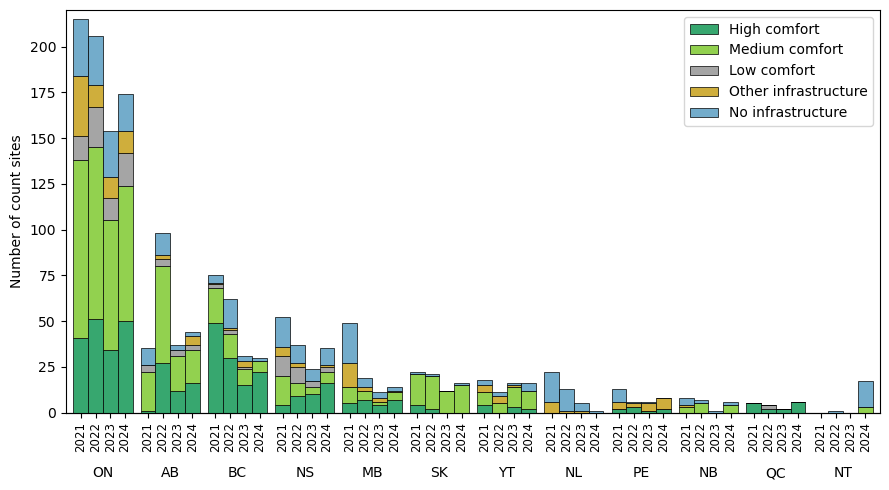

In [129]:
colour_lightness = False

fig, ax = plt.subplots(figsize = (9,5))

bottom = np.zeros(len(provinces))

xpos = np.arange(len(provinces))

width = 0.22
count = 0

for label, group in canbics_provinces.groupby(['year', 'comfort_class_sort']):

    group['combined_comfort_class'].unique()

    if group['combined_comfort_class'].unique() == 'High': # reset the plot bottom
        bottom = np.zeros(len(provinces))

    #print(bottom)

    # add zeros for missing data
    missing_provinces = set(provinces) - set(group['province_abbr'])
    df = pd.DataFrame()
    df['province_abbr'] = list(group['province_abbr']) + list(missing_provinces)
    df['count_sites'] = list(group['bike_total']) + [0]*len(missing_provinces)
    # sort by desired province order
    df = df.sort_values(by = 'province_abbr', key=lambda x: x.map(sorterIndex))

    if colour_lightness == True:
        c = adjust_lightness(colors[group['comfort_class_sort'].unique()], amount = 0.5+ 0.25*(label[0]-2021))
    else:
        c = colors[group['comfort_class_sort'].unique()]
    
    ax.bar(xpos + width*(label[0]-2021), df['count_sites'], bottom = bottom, width = width,  
           color = c, edgecolor = 'k', linewidth = 0.5)
    bottom += np.array(df['count_sites'])

    count += 1

ax.legend(handles=handles);
ax.set_xticks(np.sort(np.concatenate([xpos, xpos + width, xpos + width*2, xpos + width*3])))
year_labels = ['2021', '2022', '2023', '2024']*len(provinces)

ax.set_xticklabels(year_labels);
ax.tick_params('x', labelrotation=90, labelsize = 8.5)

provinces_label = []
for prov in provinces:
    provinces_label.append('\n\n\n' + prov)

sec = ax.secondary_xaxis(location=0)
sec.set_xticks((xpos + width*2-width/2), labels=provinces_label)
sec.tick_params('x', length=0)

ax.set_xlim(-width,11+4*width)
ax.set_ylim(0, 220)

ax.set_ylabel("Number of count sites")

plt.tight_layout()

plt.savefig("count_site_canbics_colourchange_{}.pdf".format(colour_lightness))
plt.savefig("count_site_canbics_colourchange_{}.png".format(colour_lightness), dpi = 300)

How many non-confomring sites are paths?

In [130]:
agg_counts_canbics[agg_counts_canbics['weekday_weekend'] != 'not'][['combined_comfort_class', 'other_cycle_facility']].value_counts()

combined_comfort_class  other_cycle_facility       
Non-conforming          Multi-use trail                73
                        Local street shared roadway    36
                        Major street shared lane       32
Name: count, dtype: int64

### Spatial Access Measures

Link to data here: https://www150.statcan.gc.ca/n1/pub/27-26-0001/272600012023001-eng.htm

In [131]:
counterpoint_to_dbuid = pd.read_csv("data/counterpoint_to_dbuid.csv")

In [132]:
# spatial access measures
sam_data = pd.read_csv("../../Madeleine_research_shared/Proximity_vs_accessibility/data/sam-msa-eng/acs_cycling.csv",
                      encoding='latin-1')

In [133]:
agg_counts = agg_counts.merge(counterpoint_to_dbuid, on = 'grouped_counterpoint_id', how = 'left')

In [134]:
agg_counts = agg_counts.merge(sam_data[['DBUID', 'acs_idx_hf', 'acs_idx_emp', 'acs_idx_srf', 'acs_idx_psef',
       'acs_idx_ef', 'acs_idx_caf', 'acs_lvl_gs-1', 'acs_lvl_gs-3',
       'acs_lvl_gs-5']], on = 'DBUID', how = 'left')

In [135]:
import statsmodels.formula.api as smf

In [136]:
cols = ['acs_idx_emp','acs_idx_hf', 'acs_idx_caf', 'acs_idx_srf', 'acs_idx_psef', 'acs_idx_ef']

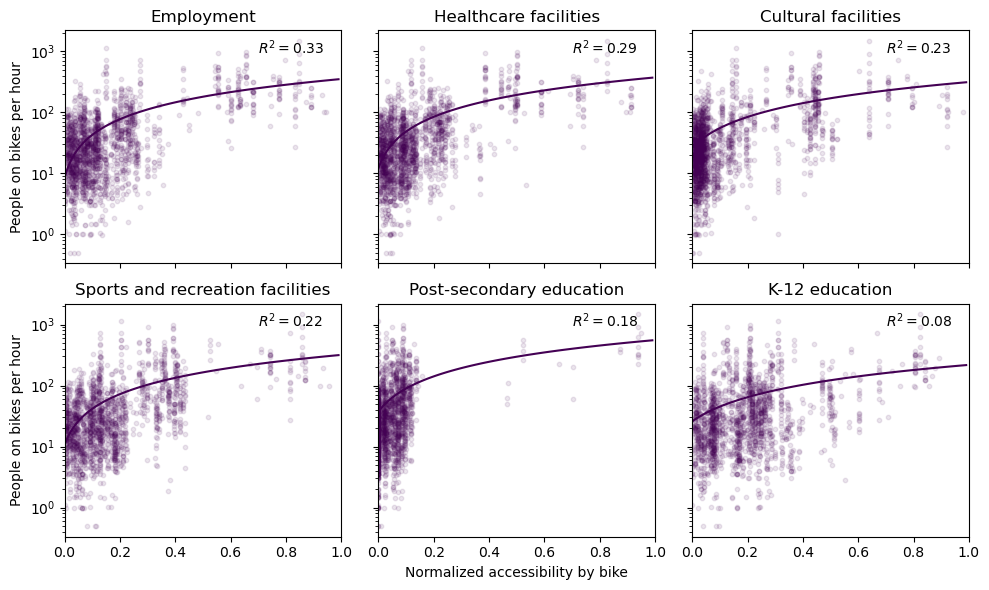

In [137]:
fig, axs = plt.subplots(2,3, figsize = (10,6))

labels = ['Employment', 'Healthcare facilities', 'Cultural facilities', 'Sports and recreation facilities', 'Post-secondary education', 'K-12 education']

xvals = np.arange(0,1,0.01)

for i, ax in enumerate(axs.flatten()):
    ax.scatter(agg_counts[cols[i]], agg_counts['bikes_per_hour'], alpha = 0.1, s = 10)

    lm = smf.ols(formula='bikes_per_hour ~ {}'.format(cols[i]), 
             data=agg_counts).fit()

    
    yvals = xvals*lm.params[cols[i]] + lm.params.Intercept
    ax.plot(xvals, yvals)

    ax.set_xlim(0,1)

    ax.set_yscale('log')

    ax.set_title(labels[i])

    ax.annotate("$R^2 = {}$".format(round(lm.rsquared,2)), xy = (0.7,0.9), xycoords='axes fraction')

axs[0,0].set_ylabel("People on bikes per hour")
axs[1,0].set_ylabel("People on bikes per hour")
axs[1,1].set_xlabel("Normalized accessibility by bike")

axs[0,0].set_xticklabels([])
axs[0,1].set_xticklabels([])
axs[0,2].set_xticklabels([])

axs[0,1].set_yticklabels([])
axs[0,2].set_yticklabels([])
axs[1,1].set_yticklabels([])
axs[1,2].set_yticklabels([])

plt.tight_layout()

plt.savefig("sam_bike_all_destinations.pdf")
plt.savefig("sam_bike_all_destinations.png", dpi = 300)

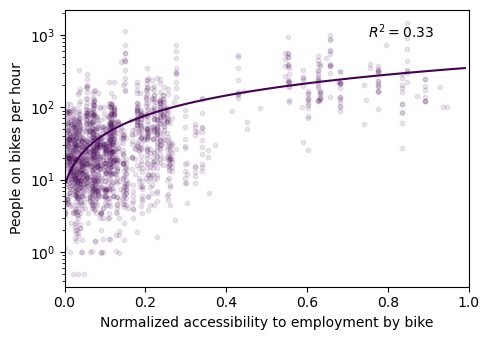

In [138]:
fig, ax = plt.subplots(figsize = (5,3.5))

# SAM
ax.scatter(agg_counts['acs_idx_emp'], agg_counts['bikes_per_hour'], alpha = 0.1, s = 10)

lm = smf.ols(formula='bikes_per_hour ~ acs_idx_emp', 
             data=agg_counts).fit()

xvals = np.arange(0,1,0.01)
yvals = xvals*lm.params.acs_idx_emp + lm.params.Intercept
ax.plot(xvals, yvals)

ax.set_yscale('log')

ax.annotate("$R^2 = {}$".format(round(lm.rsquared,2)), xy = (0.75,0.9), xycoords='axes fraction')

ax.set_ylabel("People on bikes per hour")
ax.set_xlabel("Normalized accessibility to employment by bike")

ax.set_xlim(0,1)

plt.tight_layout()

plt.savefig("bikes_per_hour_vs_SAM.png", dpi = 300)
plt.savefig("bikes_per_hour_vs_SAM.pdf")

In [139]:
cols = ['acs_idx_emp','acs_idx_hf', 'acs_idx_caf', 'acs_idx_srf', 'acs_idx_psef', 'acs_idx_ef']

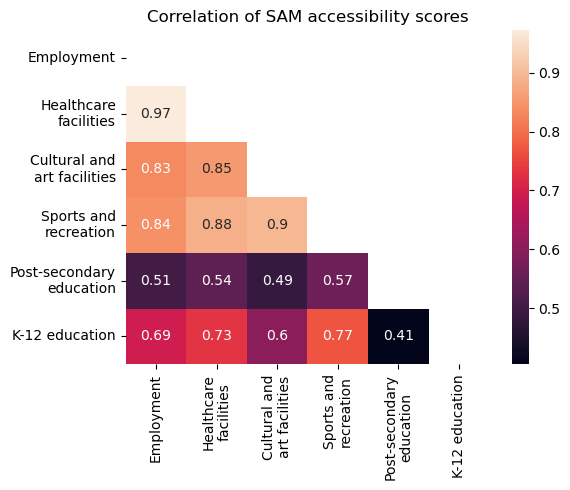

In [140]:
fig, ax = plt.subplots(figsize = (6,5))
corr = agg_counts[cols].corr()
matrix = np.triu(corr)

sns.heatmap(corr, annot=True, ax = ax, mask = matrix)
ax.set_title('Correlation of SAM accessibility scores')

labels = ['Employment', 'Healthcare\nfacilities', 'Cultural and\nart facilities', 'Sports and\nrecreation', 'Post-secondary\neducation', 'K-12 education']
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
plt.tight_layout()
plt.savefig("sam_correlations_heatmap.pdf")

### Catplot of regression model results

In [141]:
res = pd.read_csv("glmm_results.csv")

In [142]:
# can substitute bootstrap CI if it finishes running
confint_wald = pd.read_csv("confint_wald.csv")
confint_boot = pd.read_csv("confint_boot.csv")

In [143]:
res['term'].values

array(['(Intercept)', 'acs_idx_emp', 'year', 'canbics1', 'canbics2',
       'canbics3', 'canbics4', 'canbics5', 'countsessionweekday_lunch',
       'countsessionweekday_afternoon',
       'countsessionweekday_late_afternoon',
       'countsessionweekend_afternoon', 'sd__(Intercept)',
       'sd__(Intercept)'], dtype=object)

In [144]:
# disambiguate random terms
res['term2'] = res['group'] + '_' + res['term']
res['term2'] = res['term2'].fillna(res['term'])

In [145]:
# just has the random effects at the start
confint_wald['term2'] = ['index_sd__(Intercept)',
       'grouped_counterpoint_id_sd__(Intercept)', '(Intercept)', 'acs_idx_emp', 'year', 'canbics1', 'canbics2',
       'canbics3', 'canbics4', 'canbics5', 
       'countsessionweekday_lunch', 'countsessionweekday_afternoon',
       'countsessionweekday_late_afternoon',
       'countsessionweekend_afternoon']

confint_wald = confint_wald.rename(columns = {'2.5 %':'5_wald', '97.5 %':'95_wald'})

In [146]:
confint_boot['term2'] = ['index_sd__(Intercept)',
       'grouped_counterpoint_id_sd__(Intercept)', '(Intercept)', 'acs_idx_emp', 'year', 'canbics1', 'canbics2',
       'canbics3', 'canbics4', 'canbics5',
       'countsessionweekday_lunch', 'countsessionweekday_afternoon',
       'countsessionweekday_late_afternoon',
       'countsessionweekend_afternoon']

confint_boot= confint_boot.rename(columns = {'2.5 %':'5_boot', '97.5 %':'95_boot'})

In [147]:
res = res.merge(confint_boot, how = 'left', on = 'term2')

### Format table for automatic display in LaTeX
- add reference categories for Can-BICS and time of day
- indent related categories
- replace p-values below threshold with $<0.0001$
- round p-values depending on significant digits
- bold significant values (make this algorithmic to facilitate other tables)
- add intercept and random effect terms

In [148]:
def format_model_table_appendix(df, table_labels_dict, confint_columns, canbics=True):
    """
    LaTeX formatting for model results table

    df should have columns ['term2',  'estimate', 'std.error', 'p.value', confint_columns[0], confint_columns[1]]

    if canbics==True, then the model includes the 5 canbics comfort classes. otherwise these rows are skipped.
    """
    
    df['variable'] = df['term2'].map(table_labels_dict)

    # select columns
    df = df[['variable', 'estimate', 'std.error', 'p.value', confint_columns[0], confint_columns[1]]]

    # round values
    for col in ['estimate',  'std.error', confint_columns[0], confint_columns[1]]:
        df.loc[:,col] = df[col].round(2)

    for col in ['estimate',  'std.error', confint_columns[0], confint_columns[1]]:
        df[col] = df[col].astype('object')

    # format p-values
    df['p.value'] = df['p.value'].astype('object')
    for i, row in df.iterrows():
        if row['p.value'] >= 10**-4:
            exponent = math.ceil(np.abs(np.log10(row['p.value'])))
            exponent = np.max([exponent, 2])
            df.loc[i, 'p.value'] = round(row['p.value'], exponent)

    for i, row in df.iterrows():
        if row['p.value'] < 0.05: # bold all entries
            for col in ['estimate', 'std.error', 'p.value', confint_columns[0], confint_columns[1]]:
                df.loc[i, col] = r'$\mathbf{' + str(row[col]) + r'}$'
        
        if row['p.value'] < 10**-4:
            df.loc[i, 'p.value'] = r'$\mathbf{<0.0001}$'

    # add dashes for random terms
    for var in ['Random effect - count ID', 'Random effect - count site']:
        df.loc[df['variable'] == var, 'std.error'] = '--'
        df.loc[df['variable'] == var, 'p.value'] = '--'

    # add extra rows
    len_curr = len(df)

    if canbics==True:
        df.loc[len_curr+1] = [r'\textbf{Can-BICS comfort class}', np.nan, np.nan, np.nan,  np.nan, np.nan]
        df.loc[len_curr+3] = [r'\hspace{3mm} No cycling infrastructure', 0, '--', '--', '--', '--']
        
    df.loc[len_curr+2] = [r'\textbf{Count session}', np.nan, np.nan,  np.nan, np.nan, np.nan]
    
    df.loc[len_curr+4] = [r'\hspace{3mm} Weekday 7-9 am', 0,  '--', '--', '--', '--']

    df.loc[len_curr+5] = [r'\hspace{6mm} (reference)',np.nan,  np.nan, np.nan, np.nan, np.nan]

    # add a second reference row
    if canbics==True:
        df.loc[len_curr+6] = [r'\hspace{6mm} (reference)',np.nan,  np.nan, np.nan, np.nan, np.nan]
    
    for i in range(2):
        df.loc[len_curr+7+i] = [r'\hspace{3mm} (standard deviation)',np.nan,  np.nan, np.nan, np.nan, np.nan]
    
    df.loc[len_curr+9] = [r'\hspace{3mm} to jobs (SAM)',np.nan, np.nan, np.nan, np.nan, np.nan]


    # indent variables
    if canbics == True:
        features = ['Weekday 11 am-1 pm', 'Weekday 2-4 pm', 'Weekday 4-6 pm', 'Weekend 12-2 pm', 
            'Low comfort infrastructure', 'Medium comfort infrastructure', 'High comfort infrastructure', 'Unpaved multi-use trail',
                   'Signed or marked shared roadway']
    else:
        features = ['Weekday 11 am-1 pm', 'Weekday 2-4 pm', 'Weekday 4-6 pm', 'Weekend 12-2 pm']
    for var in features:
        df.loc[df['variable'] == var, 'variable'] = r'\hspace{3mm} ' + var

    if canbics == True:
        sort_order = [0,2,1,7,8,9,10,11,15,16,17,18,19,21,4,5,12,13,6,14,20,22,3]

    else:
        sort_order = [0,2,1,7,8,9,10,11,13,4,5,6,12,14,3]
        
    df['sort'] = sort_order
    
    return df

In [149]:
def format_model_table(df, table_labels_dict, confint_columns, canbics=True):
    """
    LaTeX formatting for model results table

    df should have columns ['term2',  'estimate', 'p.value', confint_columns[0], confint_columns[1]]

    if canbics==True, then the model includes the 5 canbics comfort classes. otherwise these rows are skipped.
    """
    
    df['variable'] = df['term2'].map(table_labels_dict)
    df['exp_estimate'] = np.exp(df['estimate'])
    df['exp_confint_l'] = np.exp(df[confint_columns[0]])
    df['exp_confint_r'] = np.exp(df[confint_columns[1]])

    # select columns
    df = df[['variable', 'exp_estimate', 'exp_confint_l', 'exp_confint_r', 'p.value']]

    # round values
    for col in [ 'exp_estimate', 'exp_confint_l', 'exp_confint_r']:
        df.loc[:,col] = df[col].round(2)

    for col in ['exp_estimate',  'exp_confint_l', 'exp_confint_r']:
        df[col] = df[col].astype('object')

    # format p-values
    df['p.value'] = df['p.value'].astype('object')
    for i, row in df.iterrows():
        if row['p.value'] >= 10**-4:
            exponent = math.ceil(np.abs(np.log10(row['p.value'])))
            exponent = np.max([exponent, 2])
            df.loc[i, 'p.value'] = round(row['p.value'], exponent)

    for i, row in df.iterrows():
        if row['p.value'] < 0.05: # bold all entries
            for col in [ 'exp_estimate', 'exp_confint_l', 'exp_confint_r', 'p.value']:
                df.loc[i, col] = r'$\mathbf{' + str(row[col]) + r'}$'
        
        if row['p.value'] < 10**-4:
            df.loc[i, 'p.value'] = r'$\mathbf{<0.0001}$'

    # add dashes for random terms
    for var in ['Random effect - count ID', 'Random effect - count site']:
        df.loc[df['variable'] == var, 'p.value'] = '--'

    # add extra rows
    len_curr = len(df)

    if canbics==True:
        df.loc[len_curr+1] = [r'\textbf{Can-BICS comfort class}', np.nan, np.nan,  np.nan, np.nan]
        df.loc[len_curr+3] = [r'\hspace{3mm} No cycling infrastructure',  1, '--',  '--', '--']
        
    df.loc[len_curr+2] = [r'\textbf{Count session}', np.nan,  np.nan, np.nan,  np.nan]
    
    df.loc[len_curr+4] = [r'\hspace{3mm} Weekday 7-9 am', 1, '--', '--', '--']

    df.loc[len_curr+5] = [r'\hspace{6mm} (reference)',np.nan,  np.nan, np.nan, np.nan]

    # add a second reference row
    if canbics==True:
        df.loc[len_curr+6] = [r'\hspace{6mm} (reference)',np.nan, np.nan, np.nan, np.nan]
    
    for i in range(2):
        df.loc[len_curr+7+i] = [r'\hspace{3mm} (standard deviation)',np.nan, np.nan, np.nan, np.nan]
    
    df.loc[len_curr+9] = [r'\hspace{3mm} to jobs (SAM)',np.nan, np.nan, np.nan, np.nan]


    # indent variables
    if canbics == True:
        features = ['Weekday 11 am-1 pm', 'Weekday 2-4 pm', 'Weekday 4-6 pm', 'Weekend 12-2 pm', 
            'Low comfort infrastructure', 'Medium comfort infrastructure', 'High comfort infrastructure', 'Unpaved multi-use trail',
                   'Signed or marked shared roadway']
    else:
        features = ['Weekday 11 am-1 pm', 'Weekday 2-4 pm', 'Weekday 4-6 pm', 'Weekend 12-2 pm']
    for var in features:
        df.loc[df['variable'] == var, 'variable'] = r'\hspace{3mm} ' + var

    if canbics == True:
        sort_order = [0,2,1,7,8,9,10,11,15,16,17,18,19,21,4,5,12,13,6,14,20,22,3]

    else:
        sort_order = [0,2,1,7,8,9,10,11,13,4,5,6,12,14,3]
        
    df['sort'] = sort_order
    
    return df

In [150]:
table_labels_dict = {'acs_idx_emp':'Cycling accessibility', 'year':'Year', 'canbics1':'Low comfort infrastructure', 'canbics2':'Medium comfort infrastructure', 
               'canbics3':'High comfort infrastructure',
       'canbics4': 'Unpaved multi-use trail',
 'canbics5': 'Signed or marked shared roadway', 
               'countsessionweekday_lunch':'Weekday 11 am-1 pm',
       'countsessionweekday_afternoon':'Weekday 2-4 pm',
       'countsessionweekday_late_afternoon': 'Weekday 4-6 pm',
       'countsessionweekend_afternoon':'Weekend 12-2 pm',
                    '(Intercept)':'Intercept',
                  'index_sd__(Intercept)':'Random effect - count ID',
                   'grouped_counterpoint_id_sd__(Intercept)': 'Random effect - count site' }

In [151]:
res_pretty = res.copy()

In [152]:
confint_columns = ['5_boot', '95_boot']
res_appendix = format_model_table_appendix(res_pretty, table_labels_dict, confint_columns, canbics=True)

In [153]:
res_appendix.sort_values(by = 'sort').drop(columns = 'sort').to_csv("glmm_full_summary.csv", sep = ',', index = None)

In [154]:
res2 = format_model_table(res_pretty, table_labels_dict, confint_columns, canbics=True)
res2.sort_values(by = 'sort').drop(columns = 'sort').to_csv("glmm_summary.csv", sep = ',', index = None)

### Model plot

In [155]:
labels_dict = {'acs_idx_emp':'Cycling accessibility', 'year':'Year', 'canbics1':'Low-comfort infrastructure', 'canbics2':'Medium comfort infrastructure', 
               'canbics3':'High comfort infrastructure',
       'canbics4':'Unpaved multi-use trail', 'canbics5':'Signed or marked shared roadway',  
               'countsessionweekday_lunch':'Weekday 11 am-1 pm',
       'countsessionweekday_afternoon':'Weekday 2-4 pm',
       'countsessionweekday_late_afternoon': 'Weekday 4-6 pm',
       'countsessionweekend_afternoon':'Weekend 12-2 pm'}

In [156]:
res_summary = res[~res['term'].str.contains('Intercept')]
res_summary['label'] = res_summary['term'].map(labels_dict)
res_summary['sort'] = [1,0,2,3,4,5,6,7,8,9,10]

In [157]:
res_summary['5%'] = res_summary['estimate'] -res_summary['std.error']*2
res_summary['95%'] = res_summary['estimate'] +res_summary['std.error']*2

In [158]:
res_summary = res_summary.sort_values(by = 'sort', ascending = False)

In [159]:
res_summary['exp_estimate'] = np.exp(res_summary['estimate'])

In [160]:
res_summary['exp_5'] = np.exp(res_summary['5_boot'])
res_summary['exp_95'] = np.exp(res_summary['95_boot'])

### Model split by Can-BICS

Show all in a single figure? Colour by infra class

In [161]:
labels = ['Full model', 'No\ninfrastructure', 'Low comfort', 'Medium\ncomfort', 'High comfort', 'Unpaved multi-\nuse trail', 'Signed or marked\nshared roadway']
cbics_colours = [nocolour, lowcolour,  mediumcolour, highcolour, nonconformcolour, nonconformcolour]

In [162]:
ylabels = ['Weekend 12-2 pm',
 'Weekday 4-6 pm',
 'Weekday 2-4 pm',
 'Weekday 11 am-1 pm',
 'Signed or marked\nshared roadway',
 'Unpaved\nmulti-use trail',
 'High comfort\ninfrastructure',
 'Medium comfort\ninfrastructure',
 'Low-comfort\ninfrastructure',
 'Cycling accessibility',
 'Year']

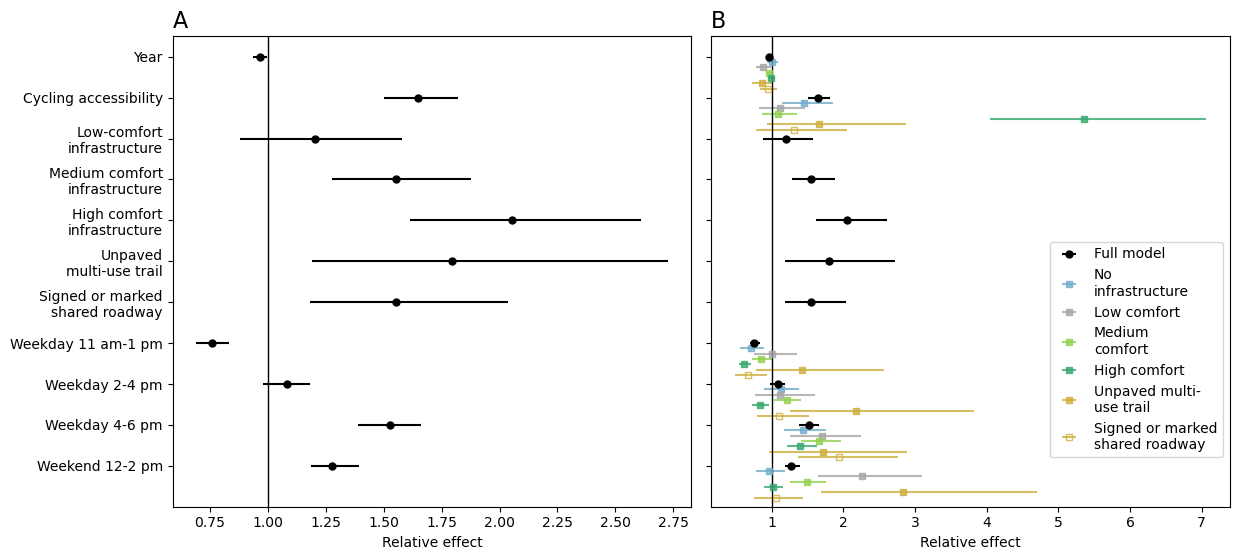

In [163]:
fig, axs = plt.subplots(1,2, figsize = (12.5,5.7))

shift = 0.13

yvals = np.arange(len(res_summary))
 
xerr = [res_summary['exp_estimate'] - res_summary['exp_5'], res_summary['exp_95']- res_summary['exp_estimate'] ]

axs[1].errorbar(res_summary['exp_estimate'], yvals, xerr = xerr, linestyle = 'None', marker = 'o', color = 'k', 
           markersize = 5, zorder = 6, label = 'Full model')

axs[0].errorbar(res_summary['exp_estimate'], yvals, xerr = xerr, linestyle = 'None', marker = 'o', color = 'k', markersize = 5)

axs[0].set_yticks(yvals)
axs[0].set_yticklabels(ylabels);
axs[0].axvline(1, color = 'k', linewidth = 1)

axs[0].set_xlabel("Relative effect")

for i in range(6):
    dat = pd.read_csv("glmm_canbics{}_results.csv".format(i))
    confint = pd.read_csv("confint_canbics{}_boot.csv".format(i))
    
    confint['term'] = ['sd__(Intercept)',
       'sd__(Intercept)', '(Intercept)', 'acs_idx_emp', 'year', 
       'countsessionweekday_lunch', 'countsessionweekday_afternoon',
       'countsessionweekday_late_afternoon',
       'countsessionweekend_afternoon']

    confint = confint.rename(columns = {'2.5 %':'5_boot', '97.5 %':'95_boot'})

    dat = dat.merge(confint, on = 'term', how = 'left')
    
    dat['exp_estimate'] = np.exp(dat['estimate'])
    dat['exp_5'] = np.exp(dat['5_boot'])
    dat['exp_95'] = np.exp(dat['95_boot'])

    dat = dat[~dat['term'].str.contains('Intercept')]
    dat['label'] = dat['term'].map(labels_dict)
    dat['sort'] = [1,0,2,3,4,5]
    dat = dat.sort_values(by = 'sort', ascending = False)

    yvals2 = np.array([0,1,2,3,9,10])
 
    xerr = [dat['exp_estimate'] - dat['exp_5'], dat['exp_95']- dat['exp_estimate'] ]

    if i == 5:
        mfc = 'None'
    else:
        mfc = cbics_colours[i]
    
    axs[1].errorbar(dat['exp_estimate'], yvals2-shift*(i+1), xerr = xerr,  linestyle = 'None', marker = 's',
               mec =cbics_colours[i], mfc = mfc, ecolor = cbics_colours[i], alpha = 0.8, markersize = 4, label = labels[i+1])


axs[1].set_yticks(yvals)
axs[1].set_yticklabels([]);

axs[0].set_ylim(-1,10.5)
axs[1].set_ylim(-1,10.5)

axs[1].axvline(1, color = 'k', linewidth = 1)
    
axs[1].set_xlabel("Relative effect")

axs[1].legend(loc = 'lower right', bbox_to_anchor = (1,0.09))

axs[0].set_title("A", fontsize = 16, loc = 'left')
axs[1].set_title("B", fontsize = 16, loc = 'left')


plt.tight_layout()

plt.savefig("model_estimates_with_canbics.pdf")
plt.savefig("model_estimates_with_canbics.png", dpi = 250)

**Format results table for Can-BICS models**

In [164]:
confint_columns = ['5_boot', '95_boot']

In [165]:
table_labels_dict_full = {'acs_idx_emp': 'Cycling accessibility to jobs (SAM)',
 'year': 'Year',
 'canbics1': 'Low comfort infrastructure',
 'canbics2': 'Medium comfort infrastructure',
 'canbics3': 'High comfort infrastructure',
 'canbics4': 'Unpaved multi-use trail',
 'canbics5': 'Signed or marked shared roadway',
 'countsessionweekday_lunch': 'Weekday 11 am-1 pm',
 'countsessionweekday_afternoon': 'Weekday 2-4 pm',
 'countsessionweekday_late_afternoon': 'Weekday 4-6 pm',
 'countsessionweekend_afternoon': 'Weekend 12-2 pm',
 '(Intercept)': 'Intercept',
 'index_sd__(Intercept)': 'Random effect - count ID (std dev)',
 'grouped_counterpoint_id_sd__(Intercept)': 'Random effect - count site (std dev)'}

In [166]:
def format_model_table_canbics_appendix(df, table_labels_dict, confint_columns):
    """
    LaTeX formatting for model results table

    df should have columns ['term2',  'estimate', 'std.error', 'p.value', confint_columns[0], confint_columns[1]]

    """
    
    df['variable'] = df['term2'].map(table_labels_dict)
    df['exp_estimate'] = np.exp(df['estimate'])

    # select columns
    df = df[['variable', 'estimate', 'exp_estimate', 'std.error', 'p.value', confint_columns[0], confint_columns[1]]]

    # round values
    for col in ['estimate', 'exp_estimate', 'std.error', confint_columns[0], confint_columns[1]]:
        df.loc[:,col] = df[col].round(2)

    for col in ['estimate', 'exp_estimate', 'std.error', confint_columns[0], confint_columns[1]]:
        df[col] = df[col].astype('object')

    # format p-values
    df['p.value'] = df['p.value'].astype('object')
    for i, row in df.iterrows():
        if row['p.value'] >= 10**-4:
            exponent = math.ceil(np.abs(np.log10(row['p.value'])))
            exponent = np.max([exponent, 2])
            df.loc[i, 'p.value'] = round(row['p.value'], exponent)

    for i, row in df.iterrows():
        if row['p.value'] < 0.05: # bold all entries
            for col in ['estimate', 'exp_estimate', 'std.error', 'p.value', confint_columns[0], confint_columns[1]]:
                df.loc[i, col] = r'$\mathbf{' + str(row[col]) + r'}$'
        
        if row['p.value'] < 10**-4:
            df.loc[i, 'p.value'] = r'$\mathbf{<0.0001}$'

    # add dashes for random terms
    for var in ['Random effect - count ID', 'Random effect - count site']:
        df.loc[df['variable'] == var, 'std.error'] = '--'
        df.loc[df['variable'] == var, 'p.value'] = '--'

    # add extra rows
    len_curr = len(df)

    df.loc[len_curr+2] = [r'\textbf{Count session}', np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]
    
    df.loc[len_curr+4] = [r'\hspace{3mm} Weekday 7-9 am (reference)', 0, 1, '--', '--', '--', '--']

    features = ['Weekday 11 am-1 pm', 'Weekday 2-4 pm', 'Weekday 4-6 pm', 'Weekend 12-2 pm']
    for var in features:
        df.loc[df['variable'] == var, 'variable'] = r'\hspace{3mm} ' + var
   
    sort_order = [0,2,1,5,6,7,8,9,11,3,4]
        
    df['sort'] = sort_order
    
    return df

In [167]:
for i in range(6):
    dat = pd.read_csv("glmm_canbics{}_results.csv".format(i))
    confint = pd.read_csv("confint_canbics{}_boot.csv".format(i))

    # disambiguate random terms
    dat['term2'] = dat['group'] + '_' + dat['term']
    dat['term2'] = dat['term2'].fillna(dat['term'])
    
    confint['term2'] = ['index_sd__(Intercept)',
       'grouped_counterpoint_id_sd__(Intercept)', '(Intercept)', 'acs_idx_emp', 'year',
       'countsessionweekday_lunch', 'countsessionweekday_afternoon',
       'countsessionweekday_late_afternoon',
       'countsessionweekend_afternoon']

    confint = confint.rename(columns = {'2.5 %':'5_boot', '97.5 %':'95_boot'})

    dat['5%'] =  dat['estimate'] - dat['std.error']*2
    dat['95%'] =  dat['estimate'] + dat['std.error']*2

    dat = dat.merge(confint, on = 'term2', how = 'left')

    dat = format_model_table_canbics_appendix(dat, table_labels_dict_full, confint_columns)

    dat.sort_values(by = 'sort').drop(columns = 'sort').to_csv("glmm_canbics{}_summary.csv".format(i), sep = ',', index = None)

In [168]:
labels =  ['No infrastructure (N=307)',
 'Low comfort (N=112)',
 'Medium comfort (N=657)',
 'High comfort (N=448)',
 'Unpaved multi-use trail (N=73)',
 'Signed or marked shared roadway (N=68)']

In [169]:
# concatenate tables for easier viewing
dfs = []
for i in range(3):
    dat = pd.read_csv("glmm_canbics{}_summary.csv".format(i))
    header = [{'variable': r'\textbf{' +labels[i] + '}', 'estimate': np.nan, 'exp_estimate': np.nan, 'std.error': np.nan, 'p.value': np.nan, '5_boot':np.nan, '95_boot':np.nan}]
    dfs.append(pd.concat([pd.DataFrame(header), dat], ignore_index=True))

In [170]:
pd.concat(dfs).to_csv("glmm_canbics_all_summary_a.csv", index = None)

In [171]:
# concatenate tables for easier viewing
dfs = []
for i in range(3,6):
    dat = pd.read_csv("glmm_canbics{}_summary.csv".format(i))
    header = [{'variable': r'\textbf{' +labels[i] + '}', 'estimate': np.nan, 'exp_estimate': np.nan, 'std.error': np.nan, 'p.value': np.nan, '5_boot':np.nan, '95_boot':np.nan}]
    dfs.append(pd.concat([pd.DataFrame(header), dat], ignore_index=True))

In [172]:
pd.concat(dfs).to_csv("glmm_canbics_all_summary_b.csv", index = None)

### Compare population sizes (for discussion)

Note that some city names don't match the CMA names, leading to a missed merge. I verified that the missing values weren't from small communities, so the discussion is not affected.

In [173]:
cma_pop = pd.read_csv("data/cma_population_2021.csv")

In [174]:
city_counts = agg_counts['geocoded_city'].value_counts().reset_index()

In [175]:
city_counts.columns = ['geocoded_city', 'num_counts']

In [176]:
city_counts_pop = city_counts.merge(cma_pop, left_on = 'geocoded_city', right_on = 'GEO_NAME', how = 'left')

In [177]:
city_counts_pop[city_counts_pop['num_counts'] >= 10].sort_values(by = 'cma_population')

,geocoded_city,num_counts,DGUID,GEO_LEVEL,GEO_NAME,cma_population,cma_pop_density_square_km
26,Canmore,11,2021S0504828,Census agglomeration,Canmore,15990.0,233.5
21,Nelson,19,2021S0504907,Census agglomeration,Nelson,19119.0,15.6
22,Yellowknife,18,2021S0504995,Census agglomeration,Yellowknife,20340.0,196.8
10,Whitehorse,61,2021S0504990,Census agglomeration,Whitehorse,31913.0,3.8
17,Charlottetown,33,2021S0504105,Census agglomeration,Charlottetown,78858.0,70.9
7,Red Deer,78,2021S0503830,Census metropolitan area,Red Deer,100844.0,966.5
16,Peterborough,34,2021S0503529,Census metropolitan area,Peterborough,128624.0,85.3
25,Moncton,18,2021S0503305,Census metropolitan area,Moncton,157717.0,61.5
23,Guelph,18,2021S0503550,Census metropolitan area,Guelph,165588.0,278.3
27,Kingston,10,2021S0503521,Census metropolitan area,Kingston,172546.0,89.9
